In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El responsable de la organización de un congreso científico ha descrito así las actividades y sus dependencias:

> Definición del programa y fechas (A) puede empezar desde el principio. Para empezar Contratación de ponentes invitados (E) hace falta haber terminado Definición del programa y fechas (A), Reserva de la sede (B) y Convocatoria de comunicaciones (C). Una vez terminadas Definición del programa y fechas (A), Reserva de la sede (B) y Convocatoria de comunicaciones (C), puede empezar Página web e inscripciones (D). Para empezar Edición del libro de actas (I) hace falta haber terminado Revisión de los trabajos recibidos (F). Reserva de la sede (B) puede empezar desde el principio. Una vez terminada Contratación de ponentes invitados (E), puede empezar Revisión de los trabajos recibidos (F). Elaboración del programa definitivo (G) sigue a Página web e inscripciones (D) y Contratación de ponentes invitados (E). Contratación de catering y viajes (H) sigue a Elaboración del programa definitivo (G). Convocatoria de comunicaciones (C) puede empezar desde el principio.

In [4]:
pregunta_1 = "1. Construya el cuadro de prelaciones inmediatas a partir del texto (una fila por actividad con sus predecesoras inmediatas).  "
pregunta_2 = "2. Construya el cuadro de prelaciones expandido e indique las actividades iniciales y finales.  "
pregunta_3 = "3. Construya el cuadro de ancestros y compruebe que ninguna prelación del texto es redundante.  "
pregunta_4 = "4. Dibuje el grafo PERT con el mínimo número de ficticias.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Construya el cuadro de prelaciones inmediatas a partir del texto (una fila por actividad con sus predecesoras inmediatas).  

2. Construya el cuadro de prelaciones expandido e indique las actividades iniciales y finales.  

3. Construya el cuadro de ancestros y compruebe que ninguna prelación del texto es redundante.  

4. Dibuje el grafo PERT con el mínimo número de ficticias.  

# Resolución

## Apartado 1

In [5]:
display(Markdown(pregunta_1))

1. Construya el cuadro de prelaciones inmediatas a partir del texto (una fila por actividad con sus predecesoras inmediatas).  

Se recorre el texto actividad por actividad anotando sólo las predecesoras que el texto nombra de forma explícita; las que se deducen por transitividad no se anotan.

In [6]:
#| tbl-cap: "Cuadro de prelaciones inmediatas"
#| label: tbl-prelaciones
datos_enunciado = pd.DataFrame([
#  activity, predecessor
    ('A'     , '---'      ),
    ('B'     , '---'      ),
    ('C'     , '---'      ),
    ('D'     , 'A,B,C'    ),
    ('E'     , 'A,B,C'    ),
    ('F'     , 'E'        ),
    ('G'     , 'D,E'      ),
    ('H'     , 'G'        ),
    ('I'     , 'F'        ),
], columns=['activity', 'predecessor']).set_index('activity')
datos_enunciado

,predecessor
activity,
A,---
B,---
C,---
D,"A,B,C"
E,"A,B,C"
F,E
G,"D,E"
H,G
I,F


In [7]:
descripciones = pd.Series({
    'A': 'Definición del programa y fechas',
    'B': 'Reserva de la sede',
    'C': 'Convocatoria de comunicaciones',
    'D': 'Página web e inscripciones',
    'E': 'Contratación de ponentes invitados',
    'F': 'Revisión de los trabajos recibidos',
    'G': 'Elaboración del programa definitivo',
    'H': 'Contratación de catering y viajes',
    'I': 'Edición del libro de actas',
}, name='Descripción')
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 2

In [8]:
display(Markdown(pregunta_2))

2. Construya el cuadro de prelaciones expandido e indique las actividades iniciales y finales.  

In [9]:
#| tbl-cap: "Cuadro de prelaciones expandido"
#| label: tbl-prelacionesExpandido
prelaciones.display_immediate_linkage_matrix()

,A,B,C,D,E,F,G,H,I
activities,,,,,,,,,
A,,,,,,,,,
B,,,,,,,,,
C,,,,,,,,,
D,True,True,True,,,,,,
E,True,True,True,,,,,,
F,,,,,True,,,,
G,,,,True,True,,,,
H,,,,,,,True,,
I,,,,,,True,,,


In [10]:
print('Actividades iniciales:', ', '.join(sorted(prelaciones.start_activities)))
print('Actividades finales:  ', ', '.join(sorted(prelaciones.end_activities)))

Actividades iniciales: A, B, C
Actividades finales:   H, I


## Apartado 3

In [11]:
display(Markdown(pregunta_3))

3. Construya el cuadro de ancestros y compruebe que ninguna prelación del texto es redundante.  

In [12]:
#| tbl-cap: "Cuadro de ancestros"
#| label: tbl-ancestros
proyecto.distant_predecessor(format='DataFrame')

,predecessors
A,----
B,----
C,----
D,"A, B, C"
E,"A, B, C"
F,"A, B, C, E"
G,"A, B, C, D, E"
H,"A, B, C, D, E, G"
I,"A, B, C, E, F"


In [13]:
G = nx.DiGraph([(p, a) for a, ps in prelaciones.immediate_predecessor.items() for p in ps])
G.add_nodes_from(datos_proyecto.index)
redundantes = sorted(set(G.edges) - set(nx.transitive_reduction(G).edges))
print('Prelaciones redundantes:', redundantes or 'ninguna')

Prelaciones redundantes: ninguna


## Apartado 4

In [14]:
display(Markdown(pregunta_4))

4. Dibuje el grafo PERT con el mínimo número de ficticias.  

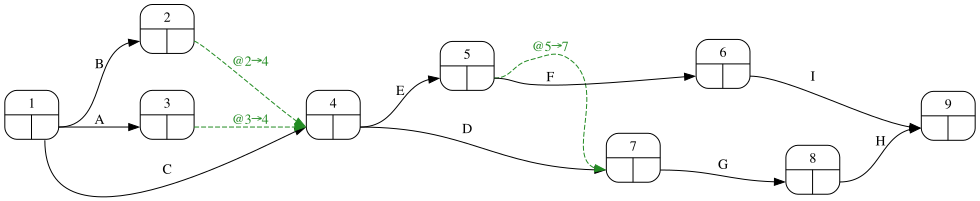

In [15]:
#| fig-cap: "Grafo PERT del proyecto"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)